# 16 — Skenario 1 (S1): rs-fMRI dengan GATv2 + Node-Attention Pooling

**Dataset:** ABIDE I + ABIDE II (turunan DCAN), 1.638 subjek, 34 situs
**Modalitas:** rs-fMRI saja
**Model:** model usulan, yaitu GATv2 + *node-attention pooling* pada graf otak, ditambah cabang linear FC multi-atlas, digabung dengan fusi atensi


| | |
| :--- | :--- |
| **Masukan** | `data/processed/kohort_dcan.csv` (1.638 subjek, fold `fold_gabungan`, notebook 09) · FC tangent 3 atlas per fold (notebook 10/11) · FC korelasi HCP untuk sisi graf (notebook 10/11) · probabilitas baseline LR `result/tabel/22_cache/C3_gab_tangent_<atlas>.npz` (dijelaskan di notebook 14) |
| **Keluaran** | `result/tabel/25_S1_*.csv` (hasil per run, per fold, prediksi per subjek, uji McNemar) · `result/metrics/S1_ringkasan.json` · `result/figure/25_*.png` · cache pelatihan `result/tabel/25_cache_5run/` |

---

## Posisi S1 dalam rangkaian skenario

Keempat skenario memakai **model, fold, dan protokol yang sama**. Pada S1–S3 yang berubah hanya **informasi yang dimasukkan**, sehingga selisih akurasi antar skenario bisa dibaca sebagai sumbangan informasi tersebut. S4 memakai informasi yang sama dengan S3; yang berubah hanya **hyperparameter**.

| Skenario | Notebook | Informasi yang dipakai |
| :---: | :---: | :--- |
| **S1** | **16 (ini)** | **rs-fMRI**: graf otak (fitur simpul = FC tangent) + cabang linear FC tangent 3 atlas |
| S2 | 17 | S1 + **sMRI**: 5 morfometri per parcel ditambahkan ke fitur simpul |
| S3 | 18 | S2 + **fenotipik** (usia, jenis kelamin, FIQ) sebagai cabang ketiga |
| S4 | 19 | **sama dengan S3**; hyperparameter dicari dengan *Optuna* di setiap fold |

**Pertanyaan S1:** seberapa baik model usulan bila hanya diberi data rs-fMRI? Angka S1 menjadi titik awal untuk S2–S4 dan dibandingkan langsung dengan baseline Logistic Regression (notebook 14).

---

## Arsitektur model

```
                    ┌──────────────────────────────────────────────────────────┐
 graf otak HCP-360  │ CABANG GRAF                                              │
 (simpul = parcel,  │ proyeksi + embedding ROI → 2 × GATv2 (4 head)            │──┐
  sisi = FC top-20) │ → node-attention pooling sadar-ROI                       │  │
                    └──────────────────────────────────────────────────────────┘  │   ┌────────────────┐
                                                                                  ├──►│ FUSI ATENSI    │──► MLP ──► [Kontrol, ASD]
                    ┌──────────────────────────────────────────────────────────┐  │   │ (bobot cabang) │
 FC tangent 3 atlas │ CABANG LINEAR                                            │──┘   └────────────────┘
 (±154 ribu nilai)  │ proyeksi PCA penuh → lapisan linear                      │
                    └──────────────────────────────────────────────────────────┘
               setiap cabang juga punya kepala klasifikasi bantu (deep supervision)
```

| Komponen | Isi | Alasan dan sumber |
| :--- | :--- | :--- |
| **Graf otak** | simpul = 360 parcel korteks HCP (Glasser); fitur simpul = **baris matriks FC tangent** (konektivitas parcel itu ke 379 ROI, termasuk subkortikal); sisi = setiap parcel dihubungkan ke **20 parcel dengan \|korelasi\| terbesar** | FC tangent adalah fitur terkuat di bangku uji fitur sebelumnya (notebook 18, sekarang di arsip) dan dijelaskan langkah demi langkah di notebook 11. Parcel korteks dipakai sebagai simpul karena sMRI (S2) juga didefinisikan pada 360 parcel ini, sehingga graf yang sama dipakai di S1–S4 |
| **GATv2** | 2 lapis, 4 *attention head*, bobot sisi sebagai fitur sisi, residual + LayerNorm | atensi dinamis antar tetangga, perbaikan GAT |
| **Node-attention pooling sadar-ROI** | skor setiap parcel → softmax di dalam satu otak → rata-rata berbobot; ditambah jalur identitas ROI | bobot atensi (α) menunjukkan **parcel mana yang paling menentukan prediksi** (dipakai di Bab 4); identitas ROI menjaga informasi "wilayah mana yang berubah" (dikembangkan di notebook 12b, sekarang di arsip) |
| **Cabang linear** | FC tangent **3 atlas** (Gordon 352, HCP 379, Markov 205 ROI) → lapisan linear | pola *wide & deep*: jalur linear menangkap pola yang memang hampir linear, jalur graf menangkap interaksi nonlinear antar-ROI. Multi-atlas terbukti lebih baik daripada satu atlas (notebook 14: 73,23% vs 70,44–72,07% per atlas) |
| **Fusi atensi** | setiap cabang menghasilkan vektor 64 dimensi; bobot setiap cabang (β) dihitung per subjek, lalu vektor digabung berbobot | model memutuskan sendiri seberapa besar mengandalkan setiap cabang, dan β bisa dilaporkan |
| **Kepala bantu** | setiap cabang punya klasifikasi sendiri, loss-nya ikut dijumlahkan (bobot 0,5) | memaksa setiap cabang belajar bermakna, dan prediksi per cabang bisa dibandingkan |

### Catatan percobaan desain fusi

Selain fusi atensi, sudah dicoba juga **penjumlahan logit** (bentuk asli Wide & Deep: logit akhir = logit linear + logit graf). Pada fold 0 hasilnya turun ke **67,38% / AUC 73,10**, padahal cabang linearnya sendiri mencapai 73,17% / AUC 81,00. Penyebabnya: logit cabang graf rata-rata **±36× lebih besar** (|logit| 7,56 vs 0,21), sehingga penjumlahan hampir sepenuhnya ditentukan oleh cabang graf yang lebih lemah. Fusi atensi tidak punya masalah ini, karena vektor setiap cabang dinormalisasi (LayerNorm) sebelum digabung. Karena itu dipakai **fusi atensi** (desain awal), dan desain ini **dikunci untuk S1–S4**. Hasil percobaan tersebut disimpan di `result/tabel/25_cache_percobaan_jumlah_logit/`.

### Tentang PCA pada cabang linear

FC tangent 3 atlas berisi ±154 ribu nilai per subjek, terlalu besar untuk lapisan linear di GPU. Nilai ini diproyeksikan ke **seluruh** komponen utama data latih (±1.300 komponen per atlas). Proyeksi ini **tidak membuang informasi** bagi model linear berpenalti L2: solusinya selalu berada di ruang yang direntang data latih (teorema representer). Hal ini sudah diuji: Logistic Regression pada skor PCA penuh memberi prediksi **100% sama** dengan Logistic Regression pada 154 ribu fitur asli.

---

## Protokol (anti-kebocoran data)

| Langkah | Dihitung dari |
| :--- | :--- |
| Acuan tangent (rata-rata geometrik kovarians) | data latih setiap fold (dihitung di notebook 10, dijelaskan di notebook 11) |
| Standardisasi fitur simpul, standardisasi + PCA cabang linear | data latih setiap fold |
| Bobot kelas (*class weight* seimbang) | data latih setiap seed |
| *Early stopping* | potongan validasi 15% dari data latih (bertingkat situs × diagnosis), **bukan** data uji |
| Ambang keputusan | tetap 0,5 (tidak dituning) |

Fold = `fold_gabungan` (5 fold, dibuat di notebook 09, sama dengan baseline LR). Hyperparameter **ditetapkan sebelum pelatihan** (mengikuti percobaan GNN awal di notebook 12b, sekarang di arsip) dan tidak diubah berdasarkan hasil uji.

### Pengulangan: 5 run

Model saraf mengandung proses acak (bobot awal, dropout, urutan batch, potongan validasi), sehingga satu kali run bisa kebetulan bagus atau kebetulan jelek. Karena itu validasi silang 5-fold **diulang 5 kali dengan seed berbeda**:

```
run 1 = seed 0 di fold 0–4  → metrik run 1
...
run 5 = seed 4 di fold 0–4  → metrik run 5
```

Hasil utama = **rata-rata ± SD antar 5 run**. Rata-rata probabilitas kelima run (*ensemble*) dilaporkan sebagai tambahan. Yang dilaporkan bukan run terbaik, karena memilih run terbaik sama dengan memilih berdasarkan data uji. Pembagian fold sama di setiap run (acuan tangent per fold dari notebook 10 terikat pada pembagian ini), sehingga variasi antar run murni berasal dari proses acak model. Baseline LR tidak diulang karena hasilnya deterministik (selalu sama).

## Lama proses

Penyiapan fitur ±1,5 menit per fold, memakai RAM ±3–4 GB. **Tutup kernel notebook lain sebelum menjalankan** (RAM laptop 12,6 GB). Pelatihan ±4 detik per epoch (RTX 3050), ±3–6 menit per seed, jadi **±2–2,5 jam** untuk 5 fold × 5 run. Hasil setiap fold disimpan ke `result/tabel/25_cache_5run/`; kalau terhenti, jalankan ulang dan fold yang sudah selesai akan dilewati.

## 1. Persiapan

In [ ]:
import gc
import sys
import json
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy import stats
from sklearn.metrics import confusion_matrix, roc_curve
from IPython.display import display
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.append(str(ROOT))
import importlib
import src.usulan
importlib.reload(src.usulan)          # selalu pakai versi terbaru src/usulan.py walau kernel belum di-restart
from src.metrics import hitung_metrik
from src.usulan import (DEVICE, ModelUsulan, buat_graf, fitur_linear_pca, fitur_simpul_baris, jalankan_cv_usulan, sisi_topk)

# ----- Parameter skenario (ditetapkan sebelum pelatihan) -----
SKENARIO = "S1"
ATLAS = {"gordon2014": 352, "hcp2016": 379, "markov2012": 205}   # jumlah ROI setiap atlas DCAN
ATLAS_GRAF = "hcp2016"
N_SIMPUL = 360                     # parcel korteks HCP (berada di urutan awal time series DCAN)
K_SISI = 20                        # setiap simpul dihubungkan ke 20 tetangga dengan |korelasi| terbesar
HIPER_MODEL = dict(hidden=64, n_layer=2, heads=4, dropout=0.5, dropout_input=0.2, dropedge=0.2, dropout_linear=0.2, bobot_bantu=0.5)
CFG_LATIH = dict(lr=1e-3, weight_decay=1e-3, batch_size=32, max_epochs=200, min_epochs=20, patience=40, val_size=0.15, seeds=(0, 1, 2, 3, 4))          # 5 seed = 5 run

PROC = ROOT / "data" / "processed"
FITUR_22 = PROC / "fitur_dcan_22"
CACHE_22 = ROOT / "result" / "tabel" / "22_cache"
TABEL_DIR = ROOT / "result" / "tabel"
FIG_DIR = ROOT / "result" / "figure"
METRIK_DIR = ROOT / "result" / "metrics"
CACHE_DIR = TABEL_DIR / "25_cache_5run"        # 25_cache = run pertama (3 seed, tanpa prediksi per run)
for d in (TABEL_DIR, FIG_DIR, METRIK_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)

kohort = pd.read_csv(PROC / "kohort_dcan.csv")
y = kohort["label"].to_numpy()
fold = kohort["fold_gabungan"].to_numpy()
situs = kohort["situs"].to_numpy()
dataset = kohort["dataset"].to_numpy()
NAMA_PARCEL = np.load(PROC / "fitur_smri_dcan" / "fitur_smri_dcan.npz", allow_pickle=True)["parcel_hcp2016"].astype(str)
print(f"Perangkat: {DEVICE} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

ringkas_data = (kohort.assign(ASD=y, Kontrol=1 - y)
                .groupby("dataset").agg(Subjek=("label", "size"), ASD=("ASD", "sum"), Kontrol=("Kontrol", "sum"), Situs=("situs", "nunique"),
                                        **{"Usia rata-rata": ("usia", "mean")}))
ringkas_data.loc["Total"] = [len(kohort), y.sum(), (1 - y).sum(), kohort["situs"].nunique(), kohort["usia"].mean()]
ringkas_data.index = ringkas_data.index.map({"abide1": "ABIDE I", "abide2": "ABIDE II", "Total": "Total"})
display(ringkas_data.round(1).style.set_caption("Kohort ABIDE I + II (DCAN)"))

Perangkat: cuda (NVIDIA GeForce RTX 3050 6GB Laptop GPU)


,Subjek,ASD,Kontrol,Situs,Usia rata-rata
dataset,,,,,
ABIDE I,886.000000,405.000000,481.000000,20.000000,16.900000
ABIDE II,752.000000,309.000000,443.000000,14.000000,15.300000
Total,1638.000000,714.000000,924.000000,34.000000,16.100000


## 2. Pembagian Fold

Fold sama dengan baseline LR (notebook 09–14), sehingga hasil S1 bisa dibandingkan langsung (uji McNemar per subjek) dengan baseline Logistic Regression. Proporsi ASD dan proporsi ABIDE I/II di setiap fold seharusnya mirip.

In [ ]:
tab_fold = pd.DataFrame({"Subjek uji": pd.Series(fold).value_counts().sort_index(),
                         "ASD (%)": pd.Series(y).groupby(fold).mean() * 100,
                         "ABIDE I": pd.Series(dataset == "abide1").groupby(fold).sum(),
                         "ABIDE II": pd.Series(dataset == "abide2").groupby(fold).sum(),
                         "Situs": pd.Series(situs).groupby(fold).nunique()})
tab_fold.index.name = "Fold"
display(tab_fold.round(1).style.set_caption("Isi setiap fold (data uji); data latih = empat fold lainnya"))

,Subjek uji,ASD (%),ABIDE I,ABIDE II,Situs
Fold,,,,,
0,328,44.500000,177,151,34
1,323,44.600000,172,151,34
2,335,44.200000,185,150,33
3,327,42.200000,177,150,33
4,325,42.500000,175,150,33


## 3. Membangun Graf Otak

Setiap subjek menjadi **satu graf**:
- **simpul**: 360 parcel korteks atlas HCP;
- **sisi**: setiap parcel dihubungkan ke 20 parcel lain dengan |korelasi| (Fisher z) terbesar, lalu dibuat simetris. Cara top-k per simpul menjamin **tidak ada simpul yang terisolasi**, berbeda dengan ambang global (mis. 20% pasangan terkuat) yang bisa membuat sebagian simpul tidak punya tetangga;
- **bobot sisi**: nilai korelasinya.

Sisi berasal dari korelasi per subjek, tidak dipelajari dari data latih, sehingga cukup dibuat sekali untuk semua fold.

In [ ]:
t0 = time.perf_counter()
KORELASI = np.load(FITUR_22 / f"korelasi_{ATLAS_GRAF}.npy", mmap_mode="r")
SISI = sisi_topk(KORELASI, ATLAS[ATLAS_GRAF], N_SIMPUL, K_SISI)
n_sisi = np.array([s[0].shape[1] // 2 for s in SISI])
derajat0 = np.bincount(SISI[0][0][0].numpy(), minlength=N_SIMPUL)
print(f"Sisi graf siap untuk {len(SISI)} subjek ({time.perf_counter() - t0:.0f} detik)")
display(pd.DataFrame({"Simpul per graf": [N_SIMPUL], "Sisi tak berarah per graf (rata-rata)": [n_sisi.mean().round(0)],
                      "Kepadatan graf (%)": [(n_sisi.mean() / (N_SIMPUL * (N_SIMPUL - 1) / 2) * 100).round(2)],
                      "Derajat minimum (subjek pertama)": [derajat0.min()], "Simpul terisolasi": [int((derajat0 == 0).sum())]}))

Sisi graf siap untuk 1638 subjek (10 detik)


,Simpul per graf,Sisi tak berarah per graf (rata-rata),Kepadatan graf (%),Derajat minimum (subjek pertama),Simpul terisolasi
0,360,5129.0,7.94,20,0


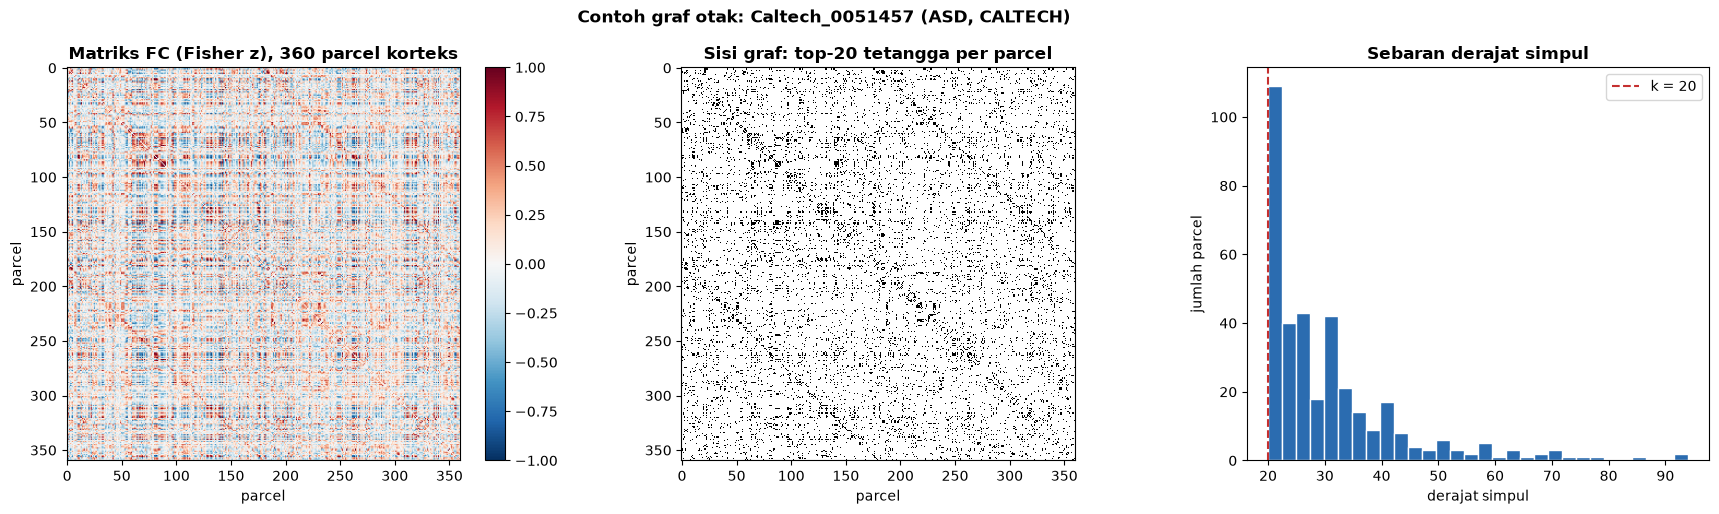

In [ ]:
from src.usulan import _matriks
contoh = 0
M = _matriks(np.asarray(KORELASI[contoh:contoh + 1]), ATLAS[ATLAS_GRAF])[0, :N_SIMPUL, :N_SIMPUL]
A = np.zeros((N_SIMPUL, N_SIMPUL))
ei = SISI[contoh][0].numpy()
A[ei[0], ei[1]] = SISI[contoh][1].numpy().ravel()

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), gridspec_kw={"width_ratios": [1, 1, 0.9]})
im = axes[0].imshow(M, cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_title("Matriks FC (Fisher z), 360 parcel korteks", fontweight="bold")
plt.colorbar(im, ax=axes[0], fraction=0.046)
axes[1].imshow(A != 0, cmap="Greys", interpolation="nearest")
axes[1].set_title(f"Sisi graf: top-{K_SISI} tetangga per parcel", fontweight="bold")
axes[2].hist(np.bincount(ei[0], minlength=N_SIMPUL), bins=30, color="#2B6CB0", edgecolor="white")
axes[2].axvline(K_SISI, color="#C53030", ls="--", label=f"k = {K_SISI}")
axes[2].set_xlabel("derajat simpul"); axes[2].set_ylabel("jumlah parcel"); axes[2].legend()
axes[2].set_title("Sebaran derajat simpul", fontweight="bold")
for ax in axes[:2]:
    ax.set_xlabel("parcel"); ax.set_ylabel("parcel")
fig.suptitle(f"Contoh graf otak: {kohort.loc[contoh, 'FILE_ID']} ({'ASD' if y[contoh] else 'Kontrol'}, {kohort.loc[contoh, 'situs']})", fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "25_1_contoh_graf_otak.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Fitur Simpul dan Fitur Cabang Linear (per Fold)

Kedua fitur bergantung pada fold karena dihitung dari **FC tangent**, yang acuannya adalah rata-rata geometrik kovarians **subjek latih** fold tersebut (berkas `tangent_<atlas>_gab_<k>.npy` dari notebook 10; langkahnya dijelaskan di notebook 11).

| Fitur | Bentuk per subjek | Pengolahan (statistik dari data latih fold) |
| :--- | :--- | :--- |
| Fitur simpul cabang graf | 360 × 379 (baris matriks tangent HCP) | standardisasi per (parcel, fitur) |
| Fitur cabang linear | ±3.900 skor PCA (3 atlas) | standardisasi per fitur → proyeksi ke seluruh komponen utama data latih |

Fungsi `siapkan_fold` dipanggil sekali per fold. Hasil fold terakhir disimpan di memori, sehingga pemeriksaan di bawah (fold 0) langsung dipakai ulang saat pelatihan.

In [ ]:
_simpan = {}

def siapkan_fold(k, idx_latih_penuh):
    """Data PyG untuk SEMUA subjek pada fold k; statistik fitur hanya dari idx_latih_penuh."""
    if _simpan.get("fold") == k:
        return _simpan["data"]
    _simpan.clear()
    gc.collect()                       # lepaskan fitur fold sebelumnya (±1 GB) sebelum membuat yang baru
    V = {a: np.load(FITUR_22 / f"tangent_{a}_gab_{k}.npy", mmap_mode="r") for a in ATLAS}
    X_simpul = fitur_simpul_baris(V[ATLAS_GRAF], ATLAS[ATLAS_GRAF], N_SIMPUL, idx_latih_penuh)
    X_linear = fitur_linear_pca([V[a] for a in ATLAS], idx_latih_penuh)
    data = buat_graf(y, X_simpul, SISI, X_linear=X_linear)
    _simpan.update(fold=k, data=data, X_simpul=X_simpul, X_linear=X_linear)
    return data

t0 = time.perf_counter()
latih0 = np.where(fold != 0)[0]
data0 = siapkan_fold(0, latih0)
Xs, Xl = _simpan["X_simpul"], _simpan["X_linear"]
display(pd.DataFrame({
    "Fitur": ["simpul (cabang graf)", "linear (cabang linear)"],
    "Bentuk": [f"{Xs.shape[0]} × {Xs.shape[1]} × {Xs.shape[2]}", f"{Xl.shape[0]} × {Xl.shape[1]}"],
    "Rata-rata data latih": [float(Xs[latih0].mean()), float(Xl[latih0].mean())],
    "SD data latih": [float(Xs[latih0].std()), float(Xl[latih0].std())],
    "Nilai tidak finit": [int((~np.isfinite(Xs)).sum()), int((~np.isfinite(Xl)).sum())],
}).round(4).style.set_caption(f"Fitur fold 0 ({time.perf_counter() - t0:.0f} detik)"))
print("Contoh satu objek graf:", data0[0])

,Fitur,Bentuk,Rata-rata data latih,SD data latih,Nilai tidak finit
0,simpul (cabang graf),1638 × 360 × 379,-0.000000,0.998700,0
1,linear (cabang linear),1638 × 3927,-0.000000,0.027600,0


Contoh satu objek graf: Data(x=[360, 379], edge_index=[2, 11108], edge_attr=[11108, 1], y=[1], x_lin=[1, 3927])


## 5. Model dan Pemeriksaan Bentuk Tensor

Sebelum pelatihan, satu batch kecil dilewatkan ke model untuk memastikan bentuk tensor setiap tahap sudah benar.

In [ ]:
def buat_model(contoh):
    return ModelUsulan(N_SIMPUL, d_simpul=contoh.x.size(1), d_linear=contoh.x_lin.size(1), **HIPER_MODEL)

from torch_geometric.loader import DataLoader
model_cek = buat_model(data0[0]).to(DEVICE).eval()
b = next(iter(DataLoader(data0[:4], batch_size=4))).to(DEVICE)
with torch.no_grad():
    logit = model_cek(b)
display(pd.DataFrame([
    {"Tahap": "input fitur simpul (4 graf digabung)", "Bentuk": tuple(b.x.shape)},
    {"Tahap": "input sisi (edge_index)", "Bentuk": tuple(b.edge_index.shape)},
    {"Tahap": "input cabang linear", "Bentuk": tuple(b.x_lin.shape)},
    {"Tahap": "bobot atensi parcel α (per subjek)", "Bentuk": tuple(model_cek.alpha().shape)},
    {"Tahap": "bobot cabang β (graf, linear)", "Bentuk": tuple(model_cek.beta_terakhir.shape)},
    {"Tahap": "keluaran logits [Kontrol, ASD]", "Bentuk": tuple(logit.shape)},
]))
param = {n: sum(p.numel() for p in model_cek.cabang[n].parameters()) for n in model_cek.nama_cabang}
param["fusi + kepala"] = sum(p.numel() for p in model_cek.parameters()) - sum(param.values())
display(pd.DataFrame({"Bagian": list(param), "Jumlah parameter": list(param.values())}).style.set_caption(
    f"Total parameter: {sum(param.values()):,}"))
assert torch.allclose(model_cek.alpha().sum(1), torch.ones(4, device=DEVICE)), "α setiap subjek harus berjumlah 1"
del model_cek, b, data0, Xs, Xl      # nama-nama ini menahan fitur fold 0 (±1 GB) di memori; lepaskan sebelum pelatihan
gc.collect()

,Tahap,Bentuk
0,input fitur simpul (4 graf digabung),"(1440, 379)"
1,input sisi (edge_index),"(2, 42624)"
2,input cabang linear,"(4, 3927)"
3,bobot atensi parcel α (per subjek),"(4, 360)"
4,"bobot cabang β (graf, linear)","(4, 2)"
5,"keluaran logits [Kontrol, ASD]","(4, 2)"


,Bagian,Jumlah parameter
0,graf,167493
1,linear,251392
2,fusi + kepala,6919


76

## 6. Pelatihan 5-Fold

| Hyperparameter | Nilai |
| :--- | :--- |
| Dimensi tersembunyi, lapis GATv2, head | 64, 2, 4 |
| Dropout (umum / input simpul / sisi / input linear) | 0,5 / 0,2 / 0,2 / 0,2 |
| Optimizer | AdamW, lr 10⁻³, weight decay 10⁻³, cosine annealing |
| Batch, epoch maksimum, *patience* | 32, 200, 40 (minimal 20 epoch) |
| Loss | cross-entropy berbobot kelas + 0,5 × rata-rata loss kepala bantu |
| Pengulangan | 5 run (seed 0–4) |

Sel berikut adalah bagian terlama. Setiap baris log menunjukkan satu seed selesai, dan setiap fold yang selesai langsung disimpan.

In [ ]:
t0 = time.perf_counter()
HASIL = jalankan_cv_usulan(y, situs, fold, siapkan_fold, buat_model, cfg=CFG_LATIH, cache_dir=CACHE_DIR)
_simpan.clear()
print(f"\nSelesai dalam {(time.perf_counter() - t0) / 60:.1f} menit (≈0 berarti semua fold dibaca dari cache).")

    fold 0 seed 0: epoch terbaik  51 | AUC val 71.71 | 4.0 menit
    fold 0 seed 1: epoch terbaik  40 | AUC val 67.25 | 3.8 menit
    fold 0 seed 2: epoch terbaik 117 | AUC val 80.09 | 7.6 menit
    fold 0 seed 3: epoch terbaik  94 | AUC val 74.26 | 6.6 menit
    fold 0 seed 4: epoch terbaik  29 | AUC val 74.72 | 3.4 menit
  fold 0: ACC 74.39 | AUC 79.46 (25 menit berjalan)
    fold 1 seed 0: epoch terbaik  55 | AUC val 76.40 | 4.5 menit
    fold 1 seed 1: epoch terbaik  54 | AUC val 79.20 | 4.6 menit
    fold 1 seed 2: epoch terbaik  45 | AUC val 75.75 | 4.1 menit
    fold 1 seed 3: epoch terbaik  56 | AUC val 74.52 | 4.7 menit
    fold 1 seed 4: epoch terbaik  28 | AUC val 76.75 | 3.3 menit
  fold 1: ACC 67.49 | AUC 76.61 (47 menit berjalan)
    fold 2 seed 0: epoch terbaik  36 | AUC val 79.07 | 3.7 menit
    fold 2 seed 1: epoch terbaik  48 | AUC val 74.99 | 4.3 menit
    fold 2 seed 2: epoch terbaik  58 | AUC val 75.76 | 4.8 menit
    fold 2 seed 3: epoch terbaik  59 | AUC val 74.7

## 7. Hasil

### 7.1 Hasil 5 run

Setiap baris adalah satu validasi silang 5-fold lengkap dengan seed berbeda. Metrik setiap run = rata-rata 5 fold. Baris terakhir adalah **hasil utama S1**: rata-rata ± SD antar run.

In [ ]:
P_LR = np.mean([np.load(CACHE_22 / f"C3_gab_tangent_{a}.npz")["p"] for a in ATLAS], axis=0)
N_RUN = HASIL["p_run"].shape[1]
KOLOM = {"accuracy": "Akurasi", "balanced": "Balanced acc.", "sensitivity": "Sensitivitas", "specificity": "Spesifisitas",
         "precision": "Presisi", "f1": "F1", "auc": "AUC"}

def metrik_per_fold(p):
    df = pd.DataFrame([{"fold": k, **hitung_metrik(y[fold == k], p[fold == k])} for k in sorted(np.unique(fold))])
    df["balanced"] = (df["sensitivity"] + df["specificity"]) / 2
    return df

def rata_fold(p):
    return metrik_per_fold(p)[list(KOLOM)].mean() * 100

tab_run = pd.DataFrame([rata_fold(HASIL["p_run"][:, r]) for r in range(N_RUN)], index=[f"run {r + 1} (seed {r})" for r in range(N_RUN)])
tab_run.columns = [f"{KOLOM[k]} (%)" for k in tab_run.columns]
tab_run_tampil = tab_run.round(2).astype(str)
tab_run_tampil.loc["Rata-rata ± SD antar run"] = [f"{m:.2f} ± {s:.2f}" for m, s in zip(tab_run.mean(), tab_run.std(ddof=1))]
display(tab_run_tampil.style.set_caption(f"S1: {N_RUN} run × 5-fold (1.638 subjek)"))
tab_run_tampil.to_csv(TABEL_DIR / "25_S1_per_run.csv")

,Akurasi (%),Balanced acc. (%),Sensitivitas (%),Spesifisitas (%),Presisi (%),F1 (%),AUC (%)
run 1 (seed 0),70.22,68.67,56.53,80.82,70.39,61.96,78.9
run 2 (seed 1),70.49,69.01,57.73,80.29,70.27,62.72,77.64
run 3 (seed 2),70.39,68.89,56.57,81.22,70.12,62.29,77.65
run 4 (seed 3),70.87,69.02,54.29,83.75,72.58,61.82,78.08
run 5 (seed 4),70.74,69.32,58.14,80.5,71.18,62.35,77.73
Rata-rata ± SD antar run,70.54 ± 0.27,68.98 ± 0.23,56.65 ± 1.50,81.31 ± 1.40,70.91 ± 1.02,62.23 ± 0.35,78.00 ± 0.53


### 7.2 Perbandingan dengan baseline

| Baris | Arti | SD |
| :--- | :--- | :--- |
| **S1 model usulan (5 run)** | hasil utama | antar run |
| S1 ensemble 5 run | probabilitas kelima run dirata-rata | antar fold |
| kepala bantu: cabang graf / cabang linear | prediksi kepala bantu satu cabang pada model yang sama (ensemble 5 run). **Bukan** model terpisah. Notebook ablasi tidak dibuat; sumbangan setiap komponen dibaca dari perbandingan berpasangan S1 → S3 | antar fold |
| Baseline LR (notebook 10) | FC tangent 3 atlas, subjek dan fold sama. Penjelasan lengkap di notebook 14; label di tabel dan grafik tetap "notebook 22" (nomor lama notebook 10) karena probabilitasnya dibuat di sana | antar fold |

In [ ]:
PRED = {"S1 ensemble 5 run": HASIL["p"], "  kepala bantu: cabang graf": HASIL["p_graf"],
        "  kepala bantu: cabang linear": HASIL["p_linear"], "Baseline LR (notebook 22)": P_LR}

def ringkas_fold(p):
    df = metrik_per_fold(p)
    return {f"{v} (%)": f"{df[k].mean() * 100:.2f} ± {df[k].std(ddof=0) * 100:.2f}" for k, v in KOLOM.items()}

tab_hasil = pd.DataFrame({"S1 model usulan (5 run)": tab_run_tampil.loc["Rata-rata ± SD antar run"].to_dict(),
                          **{n: ringkas_fold(p) for n, p in PRED.items()}}).T
display(tab_hasil.style.set_caption("S1 vs baseline"))

per_fold = metrik_per_fold(HASIL["p"]).set_index("fold")[list(KOLOM)] * 100
per_fold["LR akurasi"] = metrik_per_fold(P_LR).set_index("fold")["accuracy"] * 100
display(per_fold.round(2).style.set_caption("S1 ensemble per fold (%)"))

tab_hasil.to_csv(TABEL_DIR / "25_S1_ringkasan.csv")
per_fold.to_csv(TABEL_DIR / "25_S1_per_fold.csv")
pd.DataFrame({"FILE_ID": kohort["FILE_ID"], "dataset": dataset, "situs": situs, "fold": fold, "y_true": y,
              "p_ensemble": HASIL["p"], **{f"p_run{r + 1}": HASIL["p_run"][:, r] for r in range(N_RUN)},
              "p_graf": HASIL["p_graf"], "p_linear": HASIL["p_linear"], "p_lr": P_LR}).to_csv(TABEL_DIR / "25_S1_prediksi.csv", index=False)
with open(METRIK_DIR / "S1_ringkasan.json", "w", encoding="utf-8") as f:
    json.dump({"skenario": SKENARIO, "notebook": "25", "n_subjek": int(len(y)), "n_run": int(N_RUN),
               "rata_rata_antar_run": tab_run.mean().round(4).to_dict(), "sd_antar_run": tab_run.std(ddof=1).round(4).to_dict(),
               "per_run": tab_run.round(4).to_dict(orient="index"), "ensemble": rata_fold(HASIL["p"]).round(4).to_dict(),
               "hiper_model": HIPER_MODEL, "cfg_latih": {k: list(v) if isinstance(v, tuple) else v for k, v in CFG_LATIH.items()},
               "k_sisi": K_SISI, "fusi": "penjumlahan logit (Wide & Deep)"}, f, indent=2)

,Akurasi (%),Balanced acc. (%),Sensitivitas (%),Spesifisitas (%),Presisi (%),F1 (%),AUC (%)
S1 model usulan (5 run),70.54 ± 0.27,68.98 ± 0.23,56.65 ± 1.50,81.31 ± 1.40,70.91 ± 1.02,62.23 ± 0.35,78.00 ± 0.53
S1 ensemble 5 run,72.45 ± 2.60,70.77 ± 2.55,57.56 ± 5.15,83.99 ± 4.31,73.88 ± 4.94,64.48 ± 3.46,79.22 ± 1.44
kepala bantu: cabang graf,68.38 ± 1.29,67.37 ± 0.97,59.15 ± 9.29,75.59 ± 8.48,66.20 ± 4.97,61.68 ± 2.81,73.60 ± 1.44
kepala bantu: cabang linear,73.12 ± 2.31,71.56 ± 2.08,59.27 ± 2.88,83.84 ± 3.62,74.17 ± 4.26,65.79 ± 2.32,80.96 ± 1.61
Baseline LR (notebook 22),73.23 ± 3.48,71.83 ± 3.48,61.14 ± 5.65,82.52 ± 3.84,73.18 ± 4.59,66.50 ± 4.52,81.35 ± 2.14


,accuracy,balanced,sensitivity,specificity,precision,f1,auc,LR akurasi
fold,,,,,,,,
0,74.390000,72.790000,58.220000,87.360000,78.700000,66.930000,79.460000,72.260000
1,67.490000,65.850000,50.690000,81.010000,68.220000,58.170000,76.610000,67.180000
2,74.030000,72.720000,61.490000,83.960000,75.210000,67.660000,81.010000,77.310000
3,72.170000,71.140000,64.490000,77.780000,67.940000,66.170000,79.200000,73.700000
4,74.150000,71.370000,52.900000,89.840000,79.350000,63.480000,79.810000,75.690000


### 7.3 Uji kebermaknaan terhadap baseline

Uji McNemar membandingkan prediksi benar/salah **per subjek** antara dua model pada subjek uji yang sama. Setiap run diuji terhadap LR, ditambah ensemble dan kepala bantu setiap cabang. Karena ada beberapa perbandingan, nilai p dikoreksi dengan metode Holm.

In [ ]:
def mcnemar(pa, pb):
    A, B = (pa >= 0.5).astype(int) == y, (pb >= 0.5).astype(int) == y
    n01, n10 = int((~A & B).sum()), int((A & ~B).sum())
    return {"Selisih akurasi (poin)": round((B.mean() - A.mean()) * 100, 2), "Hanya benar di model": n01, "Hanya benar di LR": n10,
            "p": stats.binomtest(n01, n01 + n10, 0.5).pvalue if n01 + n10 else 1.0}

UJI = {**{f"S1 run {r + 1}": HASIL["p_run"][:, r] for r in range(N_RUN)}, **{n: p for n, p in PRED.items() if not n.startswith("Baseline")}}
uji = pd.DataFrame([{"Model (dibanding baseline LR)": n.strip(), **mcnemar(P_LR, p)} for n, p in UJI.items()])
urut = np.argsort(uji["p"].to_numpy())
holm = np.minimum(1, np.maximum.accumulate(uji["p"].to_numpy()[urut] * (len(uji) - np.arange(len(uji)))))
uji.loc[uji.index[urut], "p Holm"] = holm
uji["Kesimpulan"] = np.where(uji["p Holm"] >= 0.05, "setara (tidak berbeda bermakna)",
                             np.where(uji["Selisih akurasi (poin)"] > 0, "lebih baik secara bermakna", "lebih rendah secara bermakna"))
display(uji.round(4).style.set_caption("Uji McNemar + koreksi Holm"))
uji.to_csv(TABEL_DIR / "25_S1_uji_mcnemar.csv", index=False)

,Model (dibanding baseline LR),Selisih akurasi (poin),Hanya benar di model,Hanya benar di LR,p,p Holm,Kesimpulan
0,S1 run 1,-3.050000,106,156,0.002400,0.016800,lebih rendah secara bermakna
1,S1 run 2,-2.750000,109,154,0.006600,0.032800,lebih rendah secara bermakna
2,S1 run 3,-2.870000,105,152,0.004000,0.024100,lebih rendah secara bermakna
3,S1 run 4,-2.380000,102,141,0.014600,0.052500,setara (tidak berbeda bermakna)
4,S1 run 5,-2.500000,110,151,0.013100,0.052500,setara (tidak berbeda bermakna)
5,S1 ensemble 5 run,-0.790000,84,97,0.372500,0.744900,setara (tidak berbeda bermakna)
6,kepala bantu: cabang graf,-4.880000,150,230,0.000000,0.000400,lebih rendah secara bermakna
7,kepala bantu: cabang linear,-0.120000,48,50,0.919600,0.919600,setara (tidak berbeda bermakna)


### 7.4 Grafik ringkasan

- **Kiri**: akurasi, balanced accuracy, dan AUC. Batang S1 = rata-rata 5 run (titik = setiap run); batang lain = ensemble/baseline (titik = setiap fold);
- **Tengah**: kurva ROC seluruh subjek uji;
- **Kanan**: confusion matrix S1 ensemble (ambang 0,5).

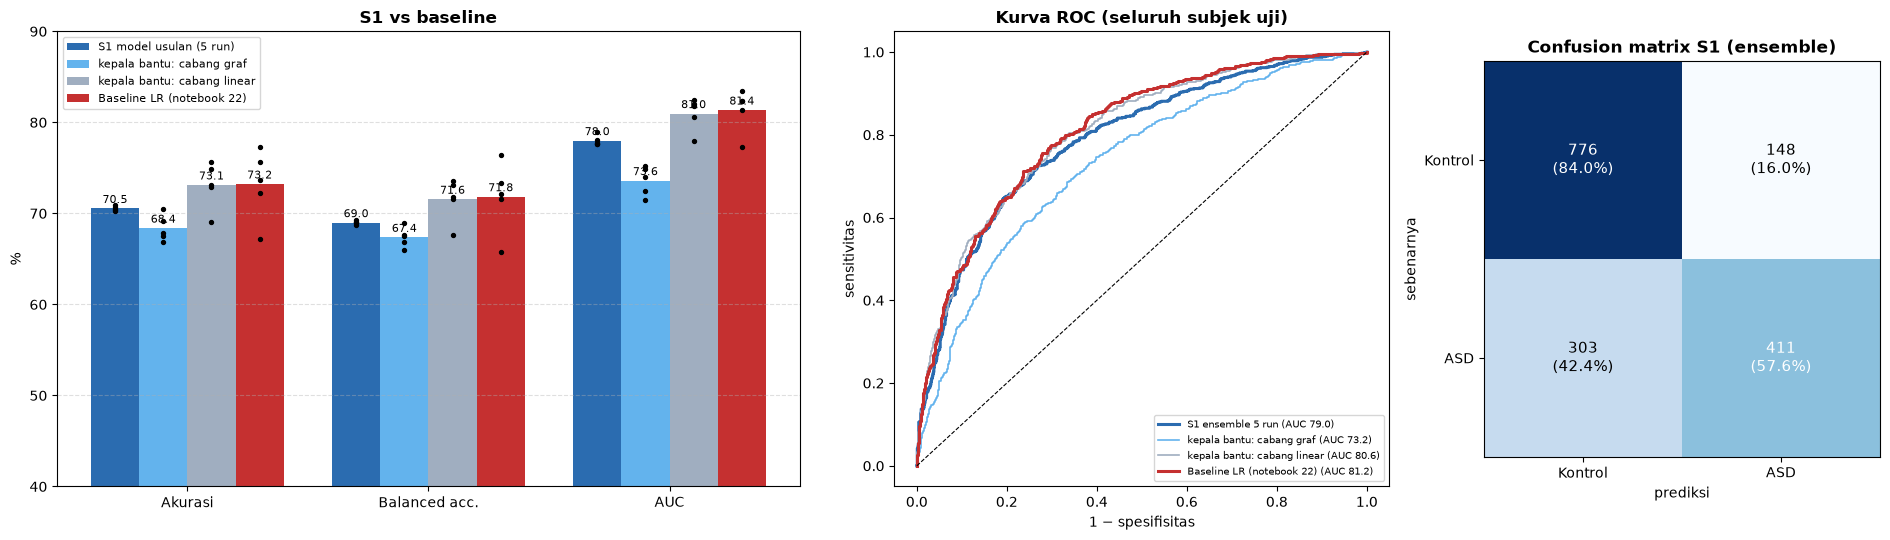

In [ ]:
WARNA = {"S1 model usulan (5 run)": "#2B6CB0", "  kepala bantu: cabang graf": "#63B3ED", "  kepala bantu: cabang linear": "#A0AEC0",
         "Baseline LR (notebook 22)": "#C53030"}
metrik_plot = [("accuracy", "Akurasi"), ("balanced", "Balanced acc."), ("auc", "AUC")]
titik = {"S1 model usulan (5 run)": [[rata_fold(HASIL["p_run"][:, r])[m] for r in range(N_RUN)] for m, _ in metrik_plot]}
for n in ("  kepala bantu: cabang graf", "  kepala bantu: cabang linear", "Baseline LR (notebook 22)"):
    df = metrik_per_fold(PRED[n])
    titik[n] = [list(df[m] * 100) for m, _ in metrik_plot]

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), gridspec_kw={"width_ratios": [1.5, 1, 0.8]})
lebar = 0.8 / len(titik)
for j, (n, nilai) in enumerate(titik.items()):
    x = np.arange(len(metrik_plot)) + (j - (len(titik) - 1) / 2) * lebar
    rata = [np.mean(v) for v in nilai]
    axes[0].bar(x, rata, lebar, color=WARNA[n], label=n.strip())
    for xi, v in zip(x, nilai):
        axes[0].scatter(np.full(len(v), xi), v, color="black", s=8, zorder=3)
    for xi, r in zip(x, rata):
        axes[0].text(xi, max(r, 40) + 0.6, f"{r:.1f}", ha="center", fontsize=8)
axes[0].set_xticks(range(len(metrik_plot))); axes[0].set_xticklabels([t for _, t in metrik_plot])
axes[0].set_ylim(40, 90); axes[0].set_ylabel("%"); axes[0].legend(fontsize=8, loc="upper left")
axes[0].set_title("S1 vs baseline", fontweight="bold"); axes[0].grid(axis="y", alpha=0.4, ls="--")

WARNA_ROC = {"S1 ensemble 5 run": "#2B6CB0", **{k: v for k, v in WARNA.items() if k != "S1 model usulan (5 run)"}}
for n, p in PRED.items():
    fpr, tpr, _ = roc_curve(y, p)
    axes[1].plot(fpr, tpr, color=WARNA_ROC[n], lw=2.2 if n.startswith("S1") or n.startswith("Baseline") else 1.2,
                 label=f"{n.strip()} (AUC {hitung_metrik(y, p)['auc'] * 100:.1f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[1].set_xlabel("1 − spesifisitas"); axes[1].set_ylabel("sensitivitas"); axes[1].legend(fontsize=7.5, loc="lower right")
axes[1].set_title("Kurva ROC (seluruh subjek uji)", fontweight="bold")

cm = confusion_matrix(y, (HASIL["p"] >= 0.5).astype(int))
axes[2].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        axes[2].text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum() * 100:.1f}%)", ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=11)
axes[2].set_xticks([0, 1]); axes[2].set_xticklabels(["Kontrol", "ASD"]); axes[2].set_yticks([0, 1]); axes[2].set_yticklabels(["Kontrol", "ASD"])
axes[2].set_xlabel("prediksi"); axes[2].set_ylabel("sebenarnya"); axes[2].set_title("Confusion matrix S1 (ensemble)", fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "25_2_hasil_s1.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.5 Akurasi per dataset dan per situs

Model dilatih pada gabungan ABIDE I + II. Di sini dicek apakah performanya **merata** pada kedua dataset dan seluruh situs, atau hanya bagus di sebagian.

,Subjek,Akurasi S1 ensemble (%),Akurasi LR (%)
ABIDE I,886,73.250000,73.360000
ABIDE II,752,71.540000,73.140000


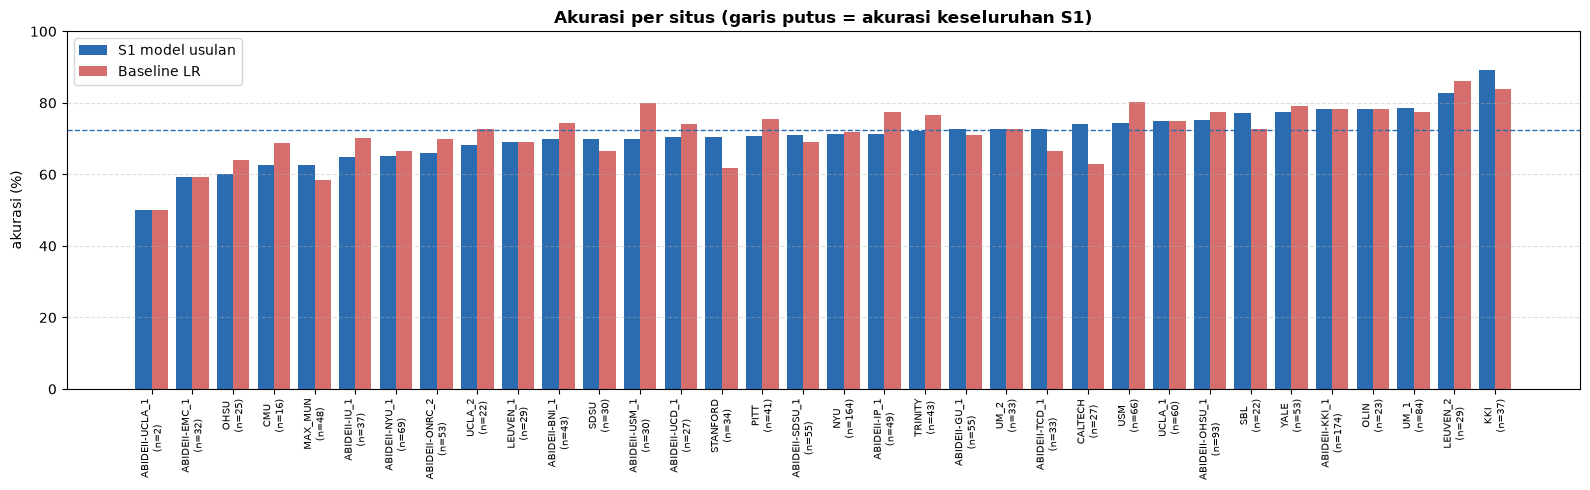

In [ ]:
benar = lambda p: ((p >= 0.5).astype(int) == y)
per_ds = pd.DataFrame({"Subjek": pd.Series(dataset).value_counts(),
                       "Akurasi S1 ensemble (%)": pd.Series(benar(HASIL["p"])).groupby(dataset).mean() * 100,
                       "Akurasi LR (%)": pd.Series(benar(P_LR)).groupby(dataset).mean() * 100})
per_ds.index = per_ds.index.map({"abide1": "ABIDE I", "abide2": "ABIDE II"})
display(per_ds.round(2).style.set_caption("Akurasi per dataset"))

per_situs = (pd.DataFrame({"situs": situs, "S1": benar(HASIL["p"]), "LR": benar(P_LR)})
             .groupby("situs").agg(n=("S1", "size"), S1=("S1", "mean"), LR=("LR", "mean")).sort_values("S1"))
per_situs[["S1", "LR"]] *= 100
fig, ax = plt.subplots(figsize=(16, 5))
x = np.arange(len(per_situs))
ax.bar(x - 0.2, per_situs["S1"], 0.4, color="#2B6CB0", label="S1 model usulan")
ax.bar(x + 0.2, per_situs["LR"], 0.4, color="#C53030", alpha=0.7, label="Baseline LR")
ax.axhline(benar(HASIL["p"]).mean() * 100, color="#2B6CB0", ls="--", lw=1)
ax.set_xticks(x); ax.set_xticklabels([f"{s}\n(n={n})" for s, n in zip(per_situs.index, per_situs["n"])], rotation=90, fontsize=7.5)
ax.set_ylabel("akurasi (%)"); ax.set_ylim(0, 100); ax.legend(); ax.grid(axis="y", alpha=0.4, ls="--")
ax.set_title("Akurasi per situs (garis putus = akurasi keseluruhan S1)", fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "25_3_akurasi_per_situs_s1.png", dpi=150, bbox_inches="tight")
plt.show()
per_situs.round(2).to_csv(TABEL_DIR / "25_S1_per_situs.csv")

### 7.6 Kurva belajar

Loss latih dan AUC validasi setiap epoch, untuk 5 fold × 5 run. Kurva ini dipakai untuk mengecek **overfitting**: loss latih terus turun, sementara AUC validasi berhenti naik. Titik merah adalah epoch yang bobotnya dipakai (AUC validasi terbaik).

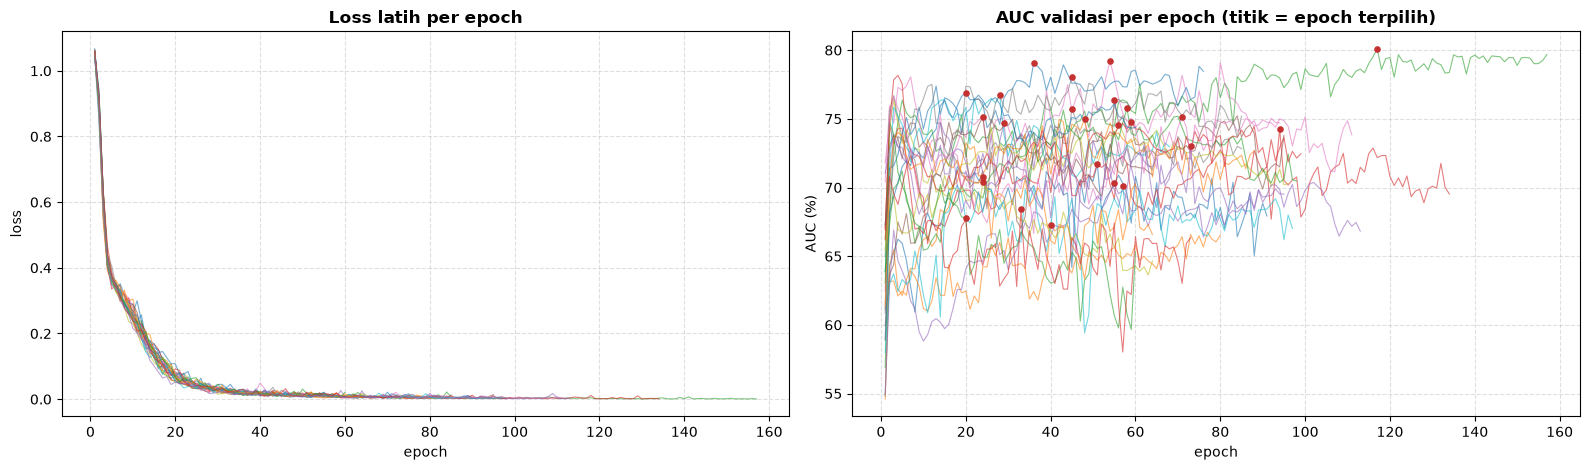

,fold,seed,epoch_terbaik,auc_val,detik
0,0,0,51,0.717000,240.062000
1,0,1,40,0.672000,227.618000
2,0,2,117,0.801000,458.303000
3,0,3,94,0.743000,394.012000
4,0,4,29,0.747000,201.084000
5,1,0,55,0.764000,272.980000
6,1,1,54,0.792000,273.818000
7,1,2,45,0.757000,248.853000
8,1,3,56,0.745000,281.226000
9,1,4,28,0.768000,199.523000


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for l in HASIL["log"]:
    r = l["riwayat"]
    axes[0].plot(r[:, 0], r[:, 1], lw=0.8, alpha=0.6)
    axes[1].plot(r[:, 0], r[:, 2] * 100, lw=0.8, alpha=0.6)
    axes[1].scatter(l["epoch_terbaik"], l["auc_val"] * 100, color="#C53030", s=14, zorder=3)
axes[0].set_title("Loss latih per epoch", fontweight="bold"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss")
axes[1].set_title("AUC validasi per epoch (titik = epoch terpilih)", fontweight="bold"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("AUC (%)")
for ax in axes:
    ax.grid(alpha=0.4, ls="--")
plt.tight_layout()
fig.savefig(FIG_DIR / "25_4_kurva_belajar_s1.png", dpi=150, bbox_inches="tight")
plt.show()
log_df = pd.DataFrame([{k: v for k, v in l.items() if k != "riwayat"} for l in HASIL["log"]])
display(log_df.round(3).style.set_caption("Ringkasan setiap seed"))
log_df.to_csv(TABEL_DIR / "25_S1_log_seed.csv", index=False)

### 7.7 Interpretasi: bobot cabang (β) dan parcel terpenting (α)

- **β**: seberapa besar model mengandalkan cabang graf vs cabang linear untuk setiap subjek;
- **α** (*node-attention pooling*): bobot setiap parcel dalam ringkasan graf. Nilai rata-rata 1/360 ≈ 0,0028 berarti "rata-rata". Parcel dengan α tinggi adalah wilayah yang paling diperhatikan model.

Bobot β dan α dihitung pada **subjek uji** setiap fold (rata-rata 5 run), lalu dirata-rata antar subjek.

,Parcel HCP,α rata-rata (×1000),α ASD (×1000),α Kontrol (×1000),Kali dari rata-rata
0,R_MT_ROI,3.113000,3.058000,3.156000,1.121000
1,L_4_ROI,3.101000,3.016000,3.168000,1.117000
2,L_STV_ROI,3.097000,3.104000,3.092000,1.115000
3,L_V4t_ROI,3.066000,3.070000,3.063000,1.104000
4,L_s32_ROI,3.063000,3.081000,3.050000,1.103000
5,L_9m_ROI,3.056000,3.102000,3.021000,1.100000
6,L_TPOJ2_ROI,3.033000,3.007000,3.054000,1.092000
7,L_PBelt_ROI,3.031000,2.989000,3.064000,1.091000
8,L_STSva_ROI,3.030000,3.023000,3.036000,1.091000
9,L_PI_ROI,3.026000,3.040000,3.015000,1.089000


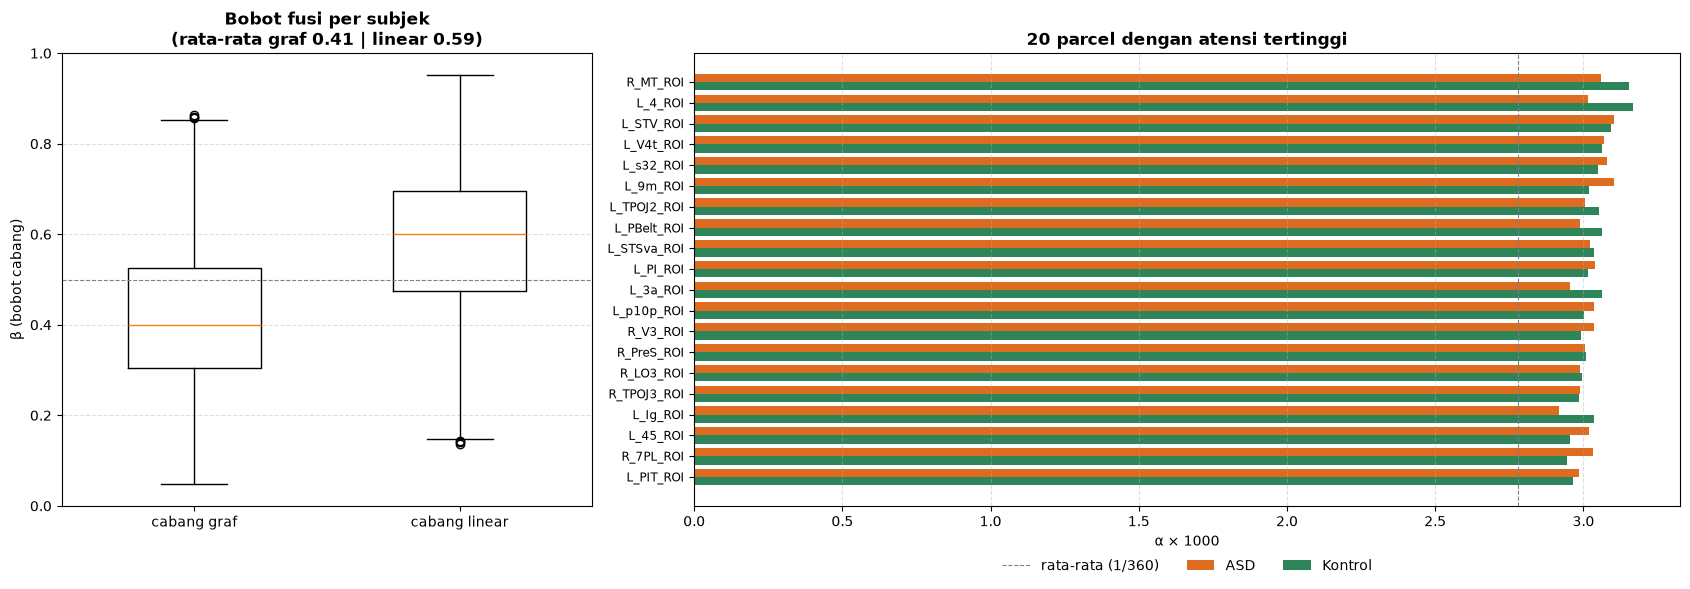

In [ ]:
beta = pd.DataFrame(HASIL["beta"], columns=["graf", "linear"])
alpha = HASIL["alpha"]
rata_alpha = alpha.mean(0)
top = np.argsort(rata_alpha)[::-1][:20]
tab_roi = pd.DataFrame({"Parcel HCP": NAMA_PARCEL[top], "α rata-rata (×1000)": rata_alpha[top] * 1000,
                        "α ASD (×1000)": alpha[y == 1][:, top].mean(0) * 1000, "α Kontrol (×1000)": alpha[y == 0][:, top].mean(0) * 1000,
                        "Kali dari rata-rata": rata_alpha[top] * N_SIMPUL})
display(tab_roi.round(3).reset_index(drop=True).style.set_caption("20 parcel dengan bobot atensi tertinggi"))
tab_roi.to_csv(TABEL_DIR / "25_S1_parcel_atensi_tertinggi.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [0.7, 1.3]})
axes[0].boxplot([beta["graf"], beta["linear"]], tick_labels=["cabang graf", "cabang linear"], widths=0.5)
axes[0].axhline(0.5, color="gray", ls="--", lw=0.8)
axes[0].set_ylabel("β (bobot cabang)"); axes[0].set_ylim(0, 1)
axes[0].set_title(f"Bobot fusi per subjek\n(rata-rata graf {beta['graf'].mean():.2f} | linear {beta['linear'].mean():.2f})", fontweight="bold")
yy = np.arange(len(top))[::-1]
axes[1].barh(yy + 0.2, tab_roi["α ASD (×1000)"], 0.4, color="#DD6B20", label="ASD")
axes[1].barh(yy - 0.2, tab_roi["α Kontrol (×1000)"], 0.4, color="#2F855A", label="Kontrol")
axes[1].axvline(1000 / N_SIMPUL, color="gray", ls="--", lw=0.8, label="rata-rata (1/360)")
axes[1].set_yticks(yy); axes[1].set_yticklabels(tab_roi["Parcel HCP"], fontsize=8.5)
axes[1].set_xlabel("α × 1000"); axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=3, frameon=False); axes[1].set_title("20 parcel dengan atensi tertinggi", fontweight="bold")
for ax in axes:
    ax.grid(axis="x" if ax is axes[1] else "y", alpha=0.4, ls="--")
plt.tight_layout()
fig.savefig(FIG_DIR / "25_5_interpretasi_atensi_s1.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Cara Membaca Hasil

| Pertanyaan | Dilihat dari |
| :--- | :--- |
| Seberapa baik model usulan dengan rs-fMRI saja? | baris **Rata-rata ± SD antar run** di tabel 7.1 |
| Seberapa stabil hasilnya bila diulang? | SD antar run (7.1): SD kecil berarti hasil tidak bergantung keberuntungan seed |
| Apakah setara, lebih baik, atau lebih rendah dari LR? | tabel 7.3 (kolom **p Holm** dan **Kesimpulan**) |
| Apakah cabang graf menangkap sinyal sendiri? | kepala bantu cabang graf (7.2): AUC jauh di atas 50% berarti graf belajar pola bermakna |
| Apakah model seimbang antara ASD dan kontrol? | sensitivitas vs spesifisitas, balanced accuracy, confusion matrix |
| Apakah model merata di kedua dataset dan semua situs? | tabel per dataset dan grafik per situs (7.5) |
| Apakah model overfitting? | kurva belajar (7.6): epoch terpilih jauh sebelum akhir pelatihan + AUC validasi stabil |
| Cabang mana yang diandalkan, dan wilayah otak mana yang penting? | β dan α (7.7). Wilayah dengan α tinggi akan dibandingkan dengan literatur ASD di Bab 4 |

Angka S1 menjadi **titik awal**. Notebook 17 (S2) memakai model dan fold yang sama, dengan tambahan fitur sMRI pada simpul graf.

### Kesimpulan

*(Diisi setelah melihat hasil.)*